# Final benchmark charts
100 examples per task (seed 42), Qwen3.5 4B/9B/27B, non-thinking. All evaluations are cache-only: a missing response or likelihood raises an error rather than loading a model.

In [2]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
from pathlib import Path
import logging

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import f1_score

from experiment_setup.benchmarks import load_examples, sample_tasks
from experiment_setup import dc_pmi, llm_critic
from experiment_setup.logging_setup import logger

CACHE = Path('full-cache')
MODELS = {'4B': 'Qwen/Qwen3.5-4B', '9B': 'Qwen/Qwen3.5-9B', '27B': 'Qwen/Qwen3.5-27B'}

In [4]:
# we kick out that one evil example
examples = [
    example
    for task in load_examples().values()
    for example in task
    if not (
        example.benchmark == "BIG-Bench-Mistake"
        and example.task == "dyck_languages"
        and example.uid == "52"
    )
]
assert len(examples) == 8585 - 1

## LLM judge
F1 measures binary error detection (not exact first-error localization) on parseable responses only. Benchmark bars pool parseable examples across task types; they are not averages of task F1 scores.

In [5]:
judge_results = {}
judge_stats = []
benchmark_f1 = []
for model, model_id in MODELS.items():
    results = llm_critic.load_run(
        examples, model_id=model_id, thinking=False,
        cache_path=CACHE / f'llm_judge_qwen35_{model.lower()}_arm.sqlite',
    )
    assert len(results) == len(examples)
    judge_results[model] = results
    task_stats = llm_critic.statistics(results)
    task_stats['model'] = model
    judge_stats.append(task_stats)
    for benchmark, group in results.groupby('benchmark', sort=False):
        valid = group[group.parse_error.isna()]
        assert len(valid), f'No parseable responses for {model}/{benchmark}'
        benchmark_f1.append({
            'model': model, 'benchmark': benchmark,
            'f1': f1_score(valid.label.notna(), valid.prediction.notna(), zero_division=0),
            'coverage': len(valid) / len(group),
        })

judge_stats = pd.concat(judge_stats, ignore_index=True)
benchmark_f1 = pd.DataFrame(benchmark_f1)
judge_table = pd.concat([
    judge_stats[['benchmark', 'task', 'model', 'f1']],
    benchmark_f1.assign(task='(all tasks)')[['benchmark', 'task', 'model', 'f1']],
], ignore_index=True).pivot(index=['benchmark', 'task'], columns='model', values='f1')
display(judge_table.reindex(columns=MODELS).round(3))
display(benchmark_f1.pivot(index='benchmark', columns='model', values='coverage').reindex(columns=MODELS).round(3).rename_axis(columns='parse coverage / model'))


model                                           4B     9B    27B
benchmark         task                                          
BIG-Bench-Mistake (all tasks)                0.810  0.766  0.848
                  dyck_languages             0.794  0.784  0.798
                  logical_deduction          1.000  0.986  0.997
                  multistep_arithmetic       0.770  0.507  0.850
                  tracking_shuffled_objects  0.548  0.556  0.683
                  word_sorting               0.876  0.786  0.960
MR-GSM8K          (all tasks)                0.782  0.791  0.877
                  POT                        0.797  0.852  0.923
                  original                   0.794  0.769  0.882
                  reversed                   0.768  0.800  0.865
ProcessBench      (all tasks)                0.854  0.880  0.914
                  gsm8k                      0.814  0.811  0.910
                  math                       0.854  0.867  0.908
                  olympiadbench              0.826  0.866  0.898
                  omnimath                   0.895  0.917  0.934

parse coverage / model,4B,9B,27B
benchmark,,,
BIG-Bench-Mistake,0.985,0.983,1.000
MR-GSM8K,0.998,0.994,1.000
ProcessBench,0.736,0.999,0.997


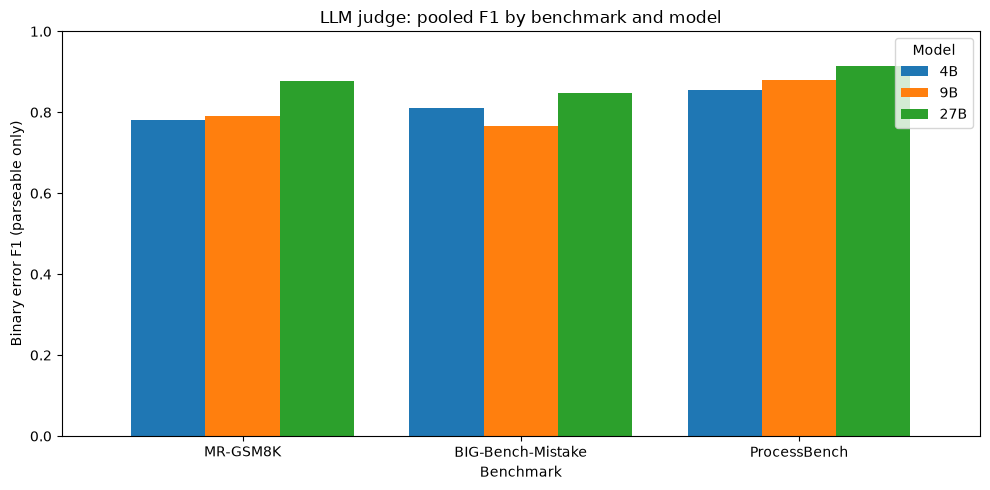

In [6]:
benchmarks = list(judge_results['4B'].benchmark.unique())
pooled_f1 = benchmark_f1.pivot(index='benchmark', columns='model', values='f1').reindex(index=benchmarks, columns=MODELS)
ax = pooled_f1.plot.bar(figsize=(10, 5), rot=0, ylim=(0, 1), width=0.8)
ax.set(xlabel='Benchmark', ylabel='Binary error F1 (parseable only)', title='LLM judge: pooled F1 by benchmark and model')
ax.legend(title='Model')
plt.tight_layout()
plt.show()


## DC-PMI
AUROC uses every step, including steps after the annotated first error. Only the first-error step is positive; all other steps are negative. For all three DC-PMI variants, **lower raw scores** predict first errors (AUROC uses negated scores). Higher perplexity predicts first errors. Each AUROC pools steps within a task type. For DC-PMI only, one-sided Mann–Whitney U p-values test whether negated scores are higher at first-error steps than at all other steps; bars with p > 0.05 are faded. Perplexity has no significance test.

In [7]:
pmi_stats = []
pmi_scores = []
pooled_pmi_f1 = []
for model, model_id in MODELS.items():
    scores = dc_pmi.load_run(
        examples, model_id=model_id,
        cache_path=CACHE / f'dc_pmi_qwen35_{model.lower()}_arm.sqlite',
    )
    assert scores[['benchmark', 'task', 'uid']].drop_duplicates().shape[0] == len(examples)
    pmi_scores.append(scores.assign(uid=model + ':' + scores.uid.astype(str)))
    summary = dc_pmi.statistics(scores)
    summary['model'] = model
    pmi_stats.append(summary)
    if model == '27B':
        for benchmark, group in scores.groupby('benchmark', sort=False):
            pooled = dc_pmi.statistics(group.assign(task='(all tasks)'))
            pooled_pmi_f1.append(pooled[['benchmark', 'metric', 'f1']])

pmi_stats = pd.concat(pmi_stats, ignore_index=True)
pooled_pmi_f1 = pd.concat(pooled_pmi_f1, ignore_index=True)
columns = pd.MultiIndex.from_product([MODELS, dc_pmi.METRICS], names=['model', 'metric'])
auc_table = pmi_stats.pivot(index=['benchmark', 'task'], columns=['model', 'metric'], values='auc')
display(auc_table.reindex(columns=columns).round(3))
p_value_table = pmi_stats.pivot(index=['benchmark', 'task'], columns=['model', 'metric'], values='p_value')
display(p_value_table.reindex(columns=columns).round(3))
f1_table = pmi_stats.pivot(index=['benchmark', 'task'], columns=['model', 'metric'], values='f1')
display(f1_table.reindex(columns=columns).round(3))
mcc_table = pmi_stats.pivot(index=['benchmark', 'task'], columns=['model', 'metric'], values='mcc')
display(mcc_table.reindex(columns=columns).round(3))


2026-11-06 09:25:20 INFO experiment_setup: Loading 8584 records from full-cache/dc_pmi_qwen35_4b_arm.sqlite
2026-11-06 09:25:27 INFO experiment_setup: Loaded records
2026-11-06 09:25:49 INFO experiment_setup: Loading 8584 records from full-cache/dc_pmi_qwen35_9b_arm.sqlite
2026-11-06 09:25:56 INFO experiment_setup: Loaded records
2026-11-06 09:26:18 INFO experiment_setup: Loading 8584 records from full-cache/dc_pmi_qwen35_27b_arm.sqlite


2026-11-06 09:26:25 INFO experiment_setup: Loaded records


model                                               4B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.629                 0.509   
                  logical_deduction              0.598                 0.478   
                  multistep_arithmetic           0.522                 0.507   
                  tracking_shuffled_objects      0.559                 0.361   
                  word_sorting                   0.643                 0.532   
MR-GSM8K          POT                            0.687                 0.421   
                  original                       0.561                 0.375   
                  reversed                       0.624                 0.363   
ProcessBench      gsm8k                          0.602                 0.443   
                  math                           0.640                 0.536   
                  olympiadbench                  0.657                 0.512   
                  omnimath                       0.613                 0.527   

model                                                                 \
metric                                      dc_pmi_question_ablation   
benchmark         task                                                 
BIG-Bench-Mistake dyck_languages                               0.662   
                  logical_deduction                            0.400   
                  multistep_arithmetic                         0.712   
                  tracking_shuffled_objects                    0.905   
                  word_sorting                                 0.524   
MR-GSM8K          POT                                          0.580   
                  original                                     0.462   
                  reversed                                     0.500   
ProcessBench      gsm8k                                        0.513   
                  math                                         0.584   
                  olympiadbench                                0.692   
                  omnimath                                     0.646   

model                                                                \
metric                                      dc_pmi_history_ablation   
benchmark         task                                                
BIG-Bench-Mistake dyck_languages                              0.576   
                  logical_deduction                           0.536   
                  multistep_arithmetic                        0.453   
                  tracking_shuffled_objects                   0.517   
                  word_sorting                                0.592   
MR-GSM8K          POT                                         0.481   
                  original                                    0.527   
                  reversed                                    0.541   
ProcessBench      gsm8k                                       0.520   
                  math                                        0.564   
                  olympiadbench                               0.529   
                  omnimath                                    0.554   

model                                               9B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.645                 0.547   
                  logical_deduction              0.600                 0.461   
                  multistep_arithmetic           0.512                 0.475   
                  tracking_shuffled_objects      0.546                 0.379   
                  word_sorting                   0.669                 0.541   
MR-GSM8K    

model                                               4B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                   NaN                 0.209   
                  logical_deduction                NaN                 0.891   
                  multistep_arithmetic             NaN                 0.363   
                  tracking_shuffled_objects        NaN                 1.000   
                  word_sorting                     NaN                 0.039   
MR-GSM8K          POT                              NaN                 0.997   
                  original                         NaN                 1.000   
                  reversed                         NaN                 1.000   
ProcessBench      gsm8k                            NaN                 0.997   
                  math                             NaN                 0.002   
                  olympiadbench                    NaN                 0.154   
                  omnimath                         NaN                 0.007   

model                                                                 \
metric                                      dc_pmi_question_ablation   
benchmark         task                                                 
BIG-Bench-Mistake dyck_languages                               0.000   
                  logical_deduction                            1.000   
                  multistep_arithmetic                         0.000   
                  tracking_shuffled_objects                    0.000   
                  word_sorting                                 0.099   
MR-GSM8K          POT                                          0.003   
                  original                                     1.000   
                  reversed                                     0.491   
ProcessBench      gsm8k                                        0.268   
                  math                                         0.000   
                  olympiadbench                                0.000   
                  omnimath                                     0.000   

model                                                                \
metric                                      dc_pmi_history_ablation   
benchmark         task                                                
BIG-Bench-Mistake dyck_languages                              0.000   
                  logical_deduction                           0.023   
                  multistep_arithmetic                        0.990   
                  tracking_shuffled_objects                   0.194   
                  word_sorting                                0.000   
MR-GSM8K          POT                                         0.741   
                  original                                    0.008   
                  reversed                                    0.000   
ProcessBench      gsm8k                                       0.167   
                  math                                        0.000   
                  olympiadbench                               0.006   
                  omnimath                                    0.000   

model                                               9B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                   NaN                 0.000   
                  logical_deduction                NaN                 0.986   
                  multistep_arithmetic             NaN                 0.888   
                  tracking_shuffled_objects        NaN                 1.000   
                  word_sorting                     NaN                 0.012   
MR-GSM8K    

model                                               4B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.104                 0.063   
                  logical_deduction              0.276                 0.226   
                  multistep_arithmetic           0.324                 0.287   
                  tracking_shuffled_objects      0.407                 0.279   
                  word_sorting                   0.199                 0.160   
MR-GSM8K          POT                            0.172                 0.141   
                  original                       0.162                 0.135   
                  reversed                       0.125                 0.092   
ProcessBench      gsm8k                          0.212                 0.181   
                  math                           0.218                 0.173   
                  olympiadbench                  0.194                 0.140   
                  omnimath                       0.209                 0.170   

model                                                                 \
metric                                      dc_pmi_question_ablation   
benchmark         task                                                 
BIG-Bench-Mistake dyck_languages                               0.200   
                  logical_deduction                            0.211   
                  multistep_arithmetic                         0.368   
                  tracking_shuffled_objects                    0.653   
                  word_sorting                                 0.153   
MR-GSM8K          POT                                          0.232   
                  original                                     0.181   
                  reversed                                     0.156   
ProcessBench      gsm8k                                        0.193   
                  math                                         0.223   
                  olympiadbench                                0.261   
                  omnimath                                     0.267   

model                                                                \
metric                                      dc_pmi_history_ablation   
benchmark         task                                                
BIG-Bench-Mistake dyck_languages                              0.074   
                  logical_deduction                           0.238   
                  multistep_arithmetic                        0.279   
                  tracking_shuffled_objects                   0.323   
                  word_sorting                                0.177   
MR-GSM8K          POT                                         0.141   
                  original                                    0.159   
                  reversed                                    0.105   
ProcessBench      gsm8k                                       0.185   
                  math                                        0.182   
                  olympiadbench                               0.147   
                  omnimath                                    0.186   

model                                               9B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.105                 0.073   
                  logical_deduction              0.284                 0.226   
                  multistep_arithmetic           0.325                 0.284   
                  tracking_shuffled_objects      0.408                 0.280   
                  word_sorting                   0.211                 0.160   
MR-GSM8K    

model                                               4B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.123                 0.032   
                  logical_deduction              0.183                 0.082   
                  multistep_arithmetic           0.200                 0.085   
                  tracking_shuffled_objects      0.325                 0.039   
                  word_sorting                   0.151                 0.094   
MR-GSM8K          POT                            0.079                 0.092   
                  original                       0.109                 0.022   
                  reversed                       0.098                 0.013   
ProcessBench      gsm8k                          0.120                 0.019   
                  math                           0.128                 0.047   
                  olympiadbench                  0.126                 0.037   
                  omnimath                       0.112                 0.043   

model                                                                 \
metric                                      dc_pmi_question_ablation   
benchmark         task                                                 
BIG-Bench-Mistake dyck_languages                               0.179   
                  logical_deduction                            0.078   
                  multistep_arithmetic                         0.244   
                  tracking_shuffled_objects                    0.597   
                  word_sorting                                 0.093   
MR-GSM8K          POT                                          0.180   
                  original                                     0.129   
                  reversed                                     0.106   
ProcessBench      gsm8k                                        0.112   
                  math                                         0.125   
                  olympiadbench                                0.198   
                  omnimath                                     0.182   

model                                                                \
metric                                      dc_pmi_history_ablation   
benchmark         task                                                
BIG-Bench-Mistake dyck_languages                              0.057   
                  logical_deduction                           0.105   
                  multistep_arithmetic                        0.050   
                  tracking_shuffled_objects                   0.160   
                  word_sorting                                0.123   
MR-GSM8K          POT                                         0.018   
                  original                                    0.070   
                  reversed                                    0.039   
ProcessBench      gsm8k                                       0.066   
                  math                                        0.062   
                  olympiadbench                               0.037   
                  omnimath                                    0.064   

model                                               9B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.131                 0.053   
                  logical_deduction              0.194                 0.075   
                  multistep_arithmetic           0.197                 0.076   
                  tracking_shuffled_objects      0.318                 0.042   
                  word_sorting                   0.204                 0.089   
MR-GSM8K    

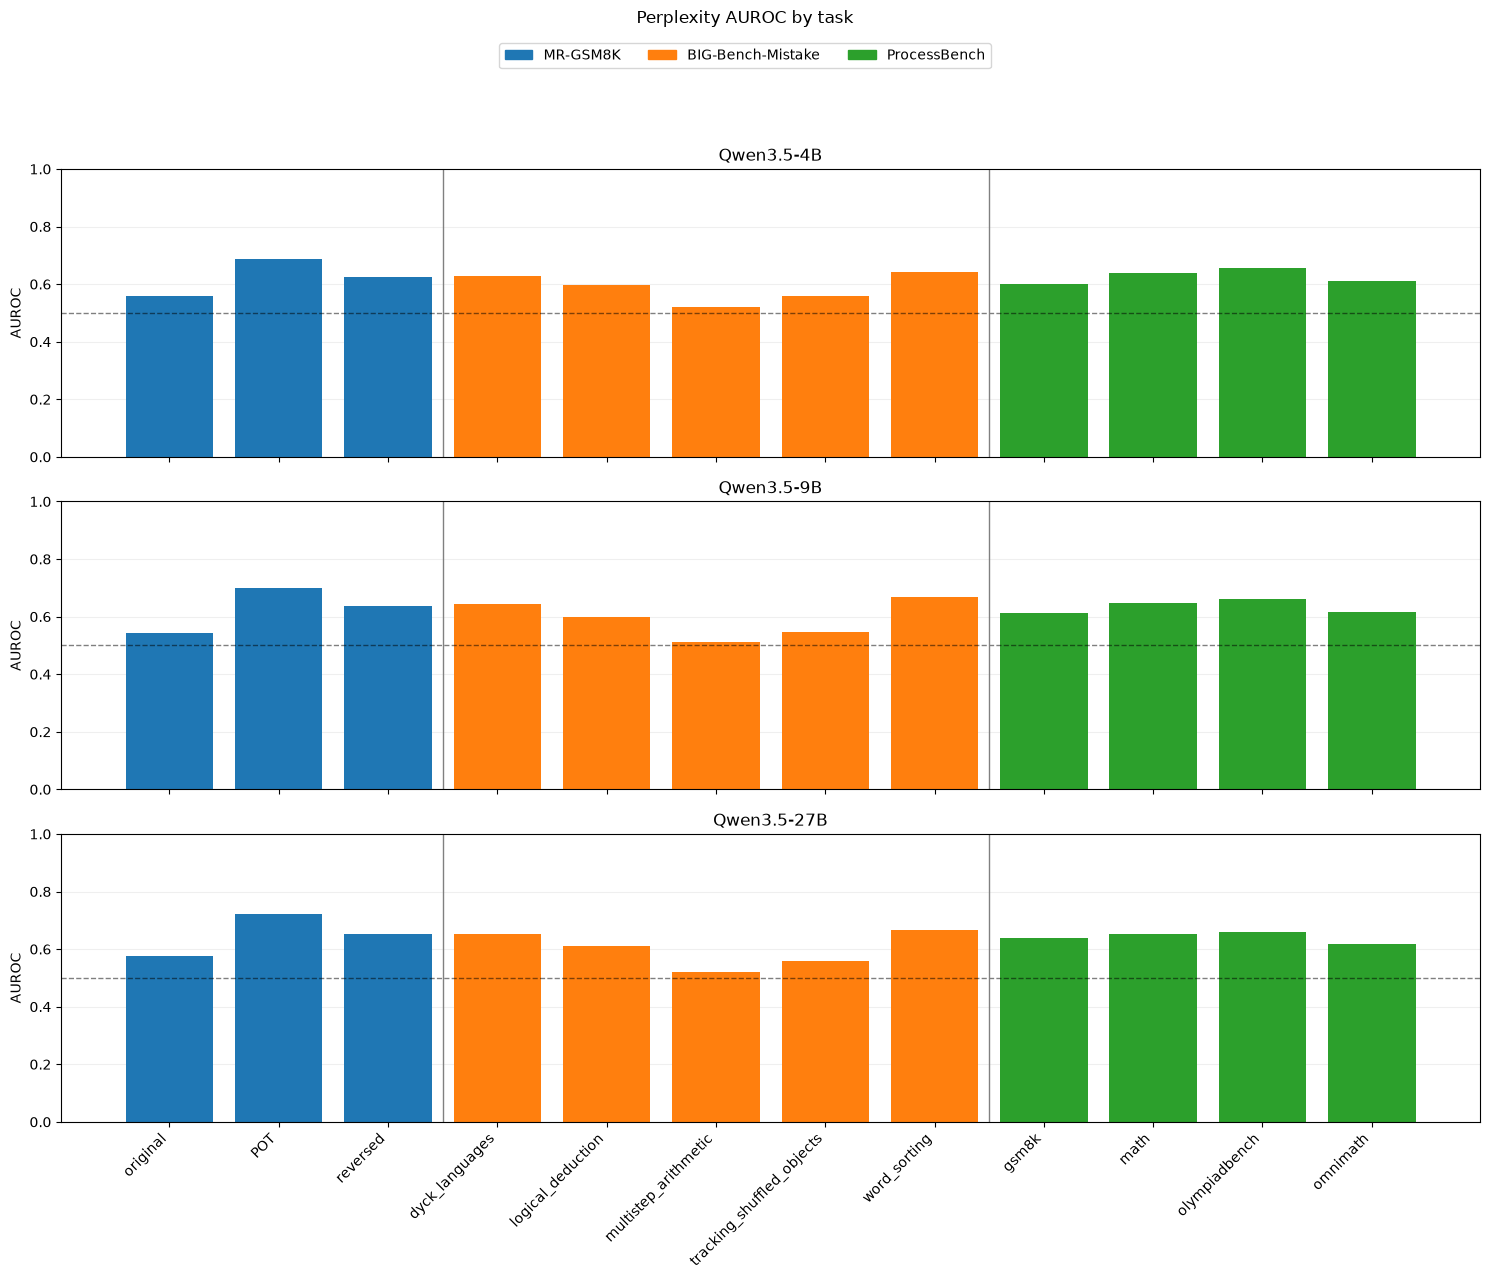

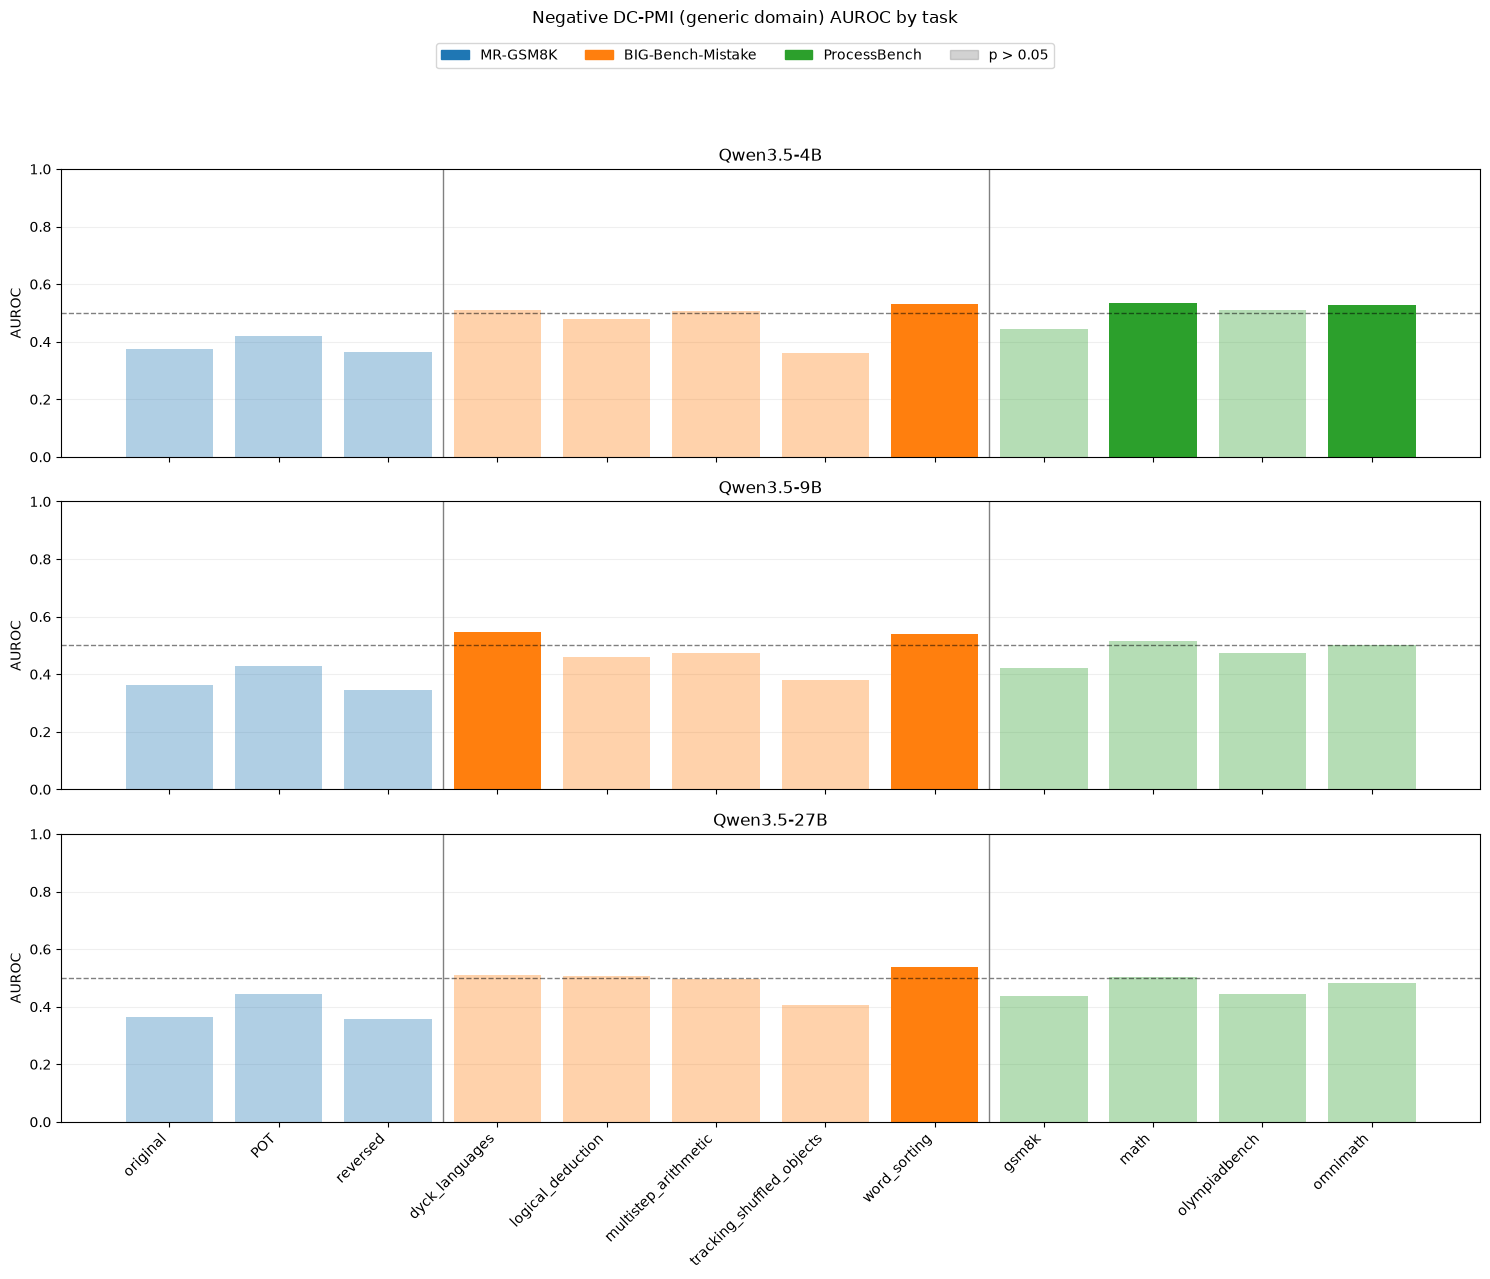

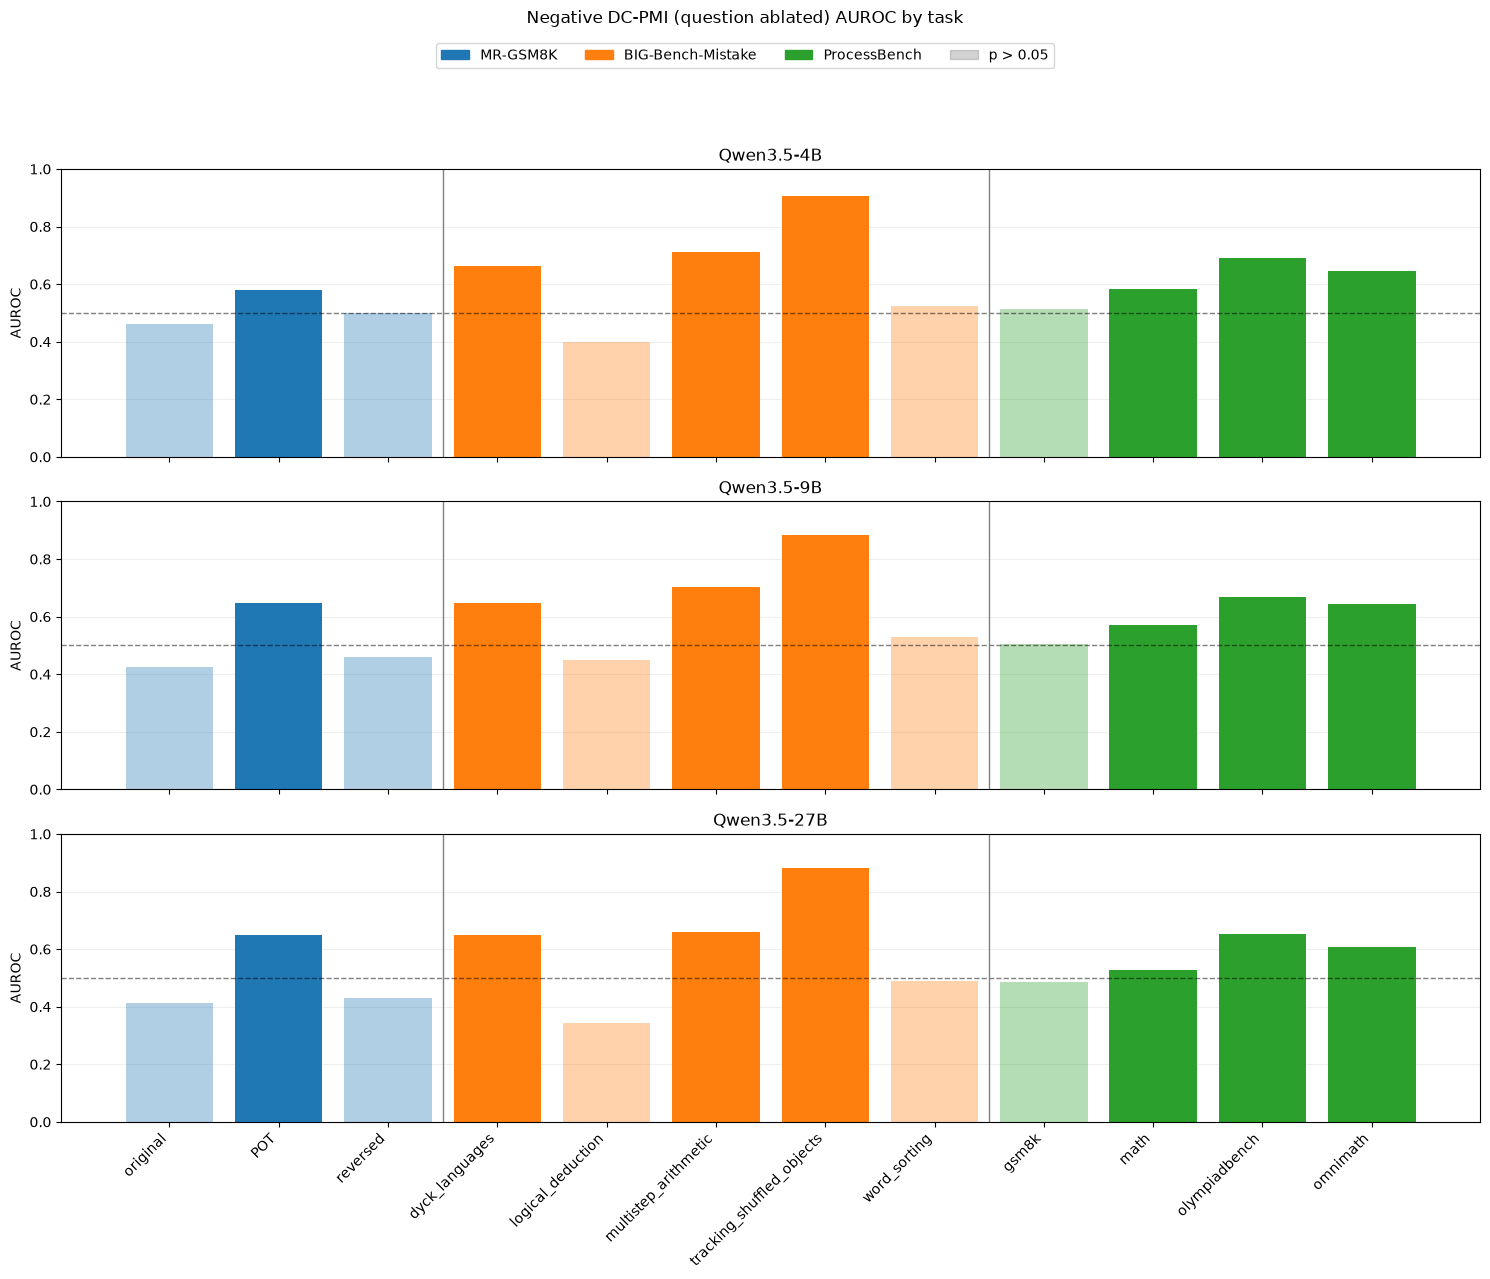

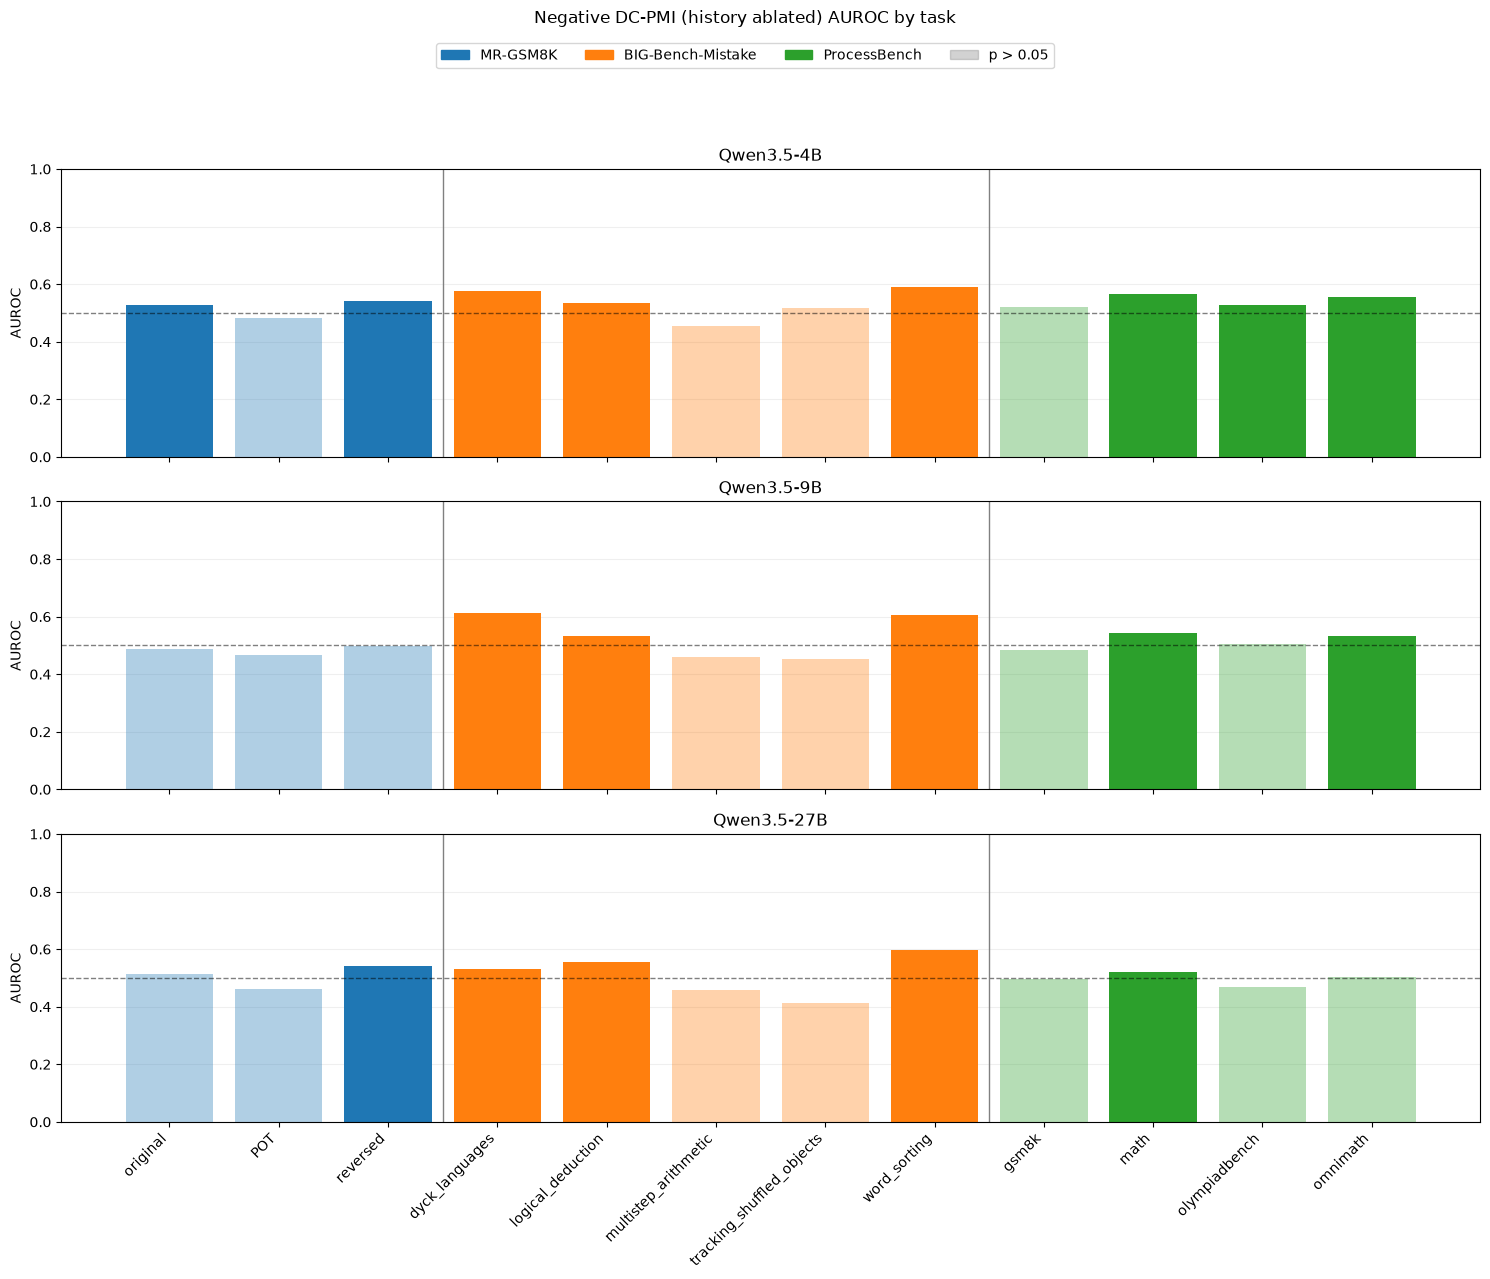

In [8]:
from experiment_setup.plots import plot_task_auc_bars

for metric in dc_pmi.METRICS:
    fig = plot_task_auc_bars(pmi_stats, metric, MODELS)
    display(fig)
    plt.close(fig)


## 27B: binary first-error F1 by benchmark

Each bar pools all task types within a benchmark. High perplexity and low question-ablated DC-PMI predict first errors. Their thresholds are tuned and evaluated on the same labeled steps (optimistic in-sample F1); the judge uses only parseable responses and predicts whether a trace contains an error, so its F1 is not directly comparable to step-level detection.


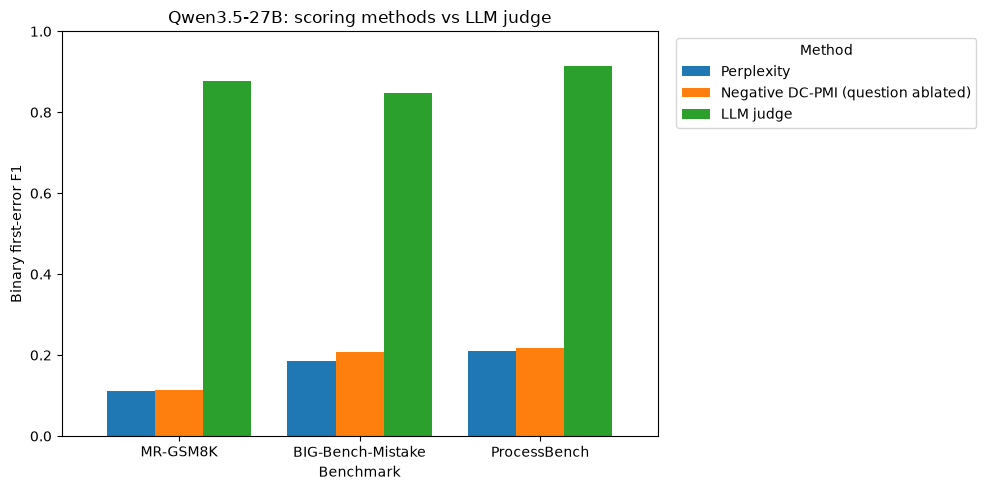

In [9]:
from experiment_setup.plots import METRIC_LABELS

chart_metrics = ('perplexity', 'dc_pmi_question_ablation')
comparison = pooled_pmi_f1.loc[pooled_pmi_f1.metric.isin(chart_metrics)].assign(
    method=lambda table: table.metric.map(METRIC_LABELS),
)[['benchmark', 'method', 'f1']]
comparison = pd.concat([
    comparison,
    benchmark_f1.loc[benchmark_f1.model == '27B', ['benchmark', 'f1']].assign(method='LLM judge'),
], ignore_index=True)
methods = [METRIC_LABELS[metric] for metric in chart_metrics] + ['LLM judge']
chart = comparison.pivot(index='benchmark', columns='method', values='f1').reindex(
    index=benchmarks, columns=methods,
)
assert chart.notna().all().all()
ax = chart.plot.bar(figsize=(10, 5), rot=0, ylim=(0, 1), width=0.8)
ax.set(xlabel='Benchmark', ylabel='Binary first-error F1', title='Qwen3.5-27B: scoring methods vs LLM judge')
ax.legend(title='Method', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 27B: first-error AUROC by benchmark

AUROC pools all steps across task types within each benchmark. Lower question-ablated DC-PMI and higher perplexity predict first errors.

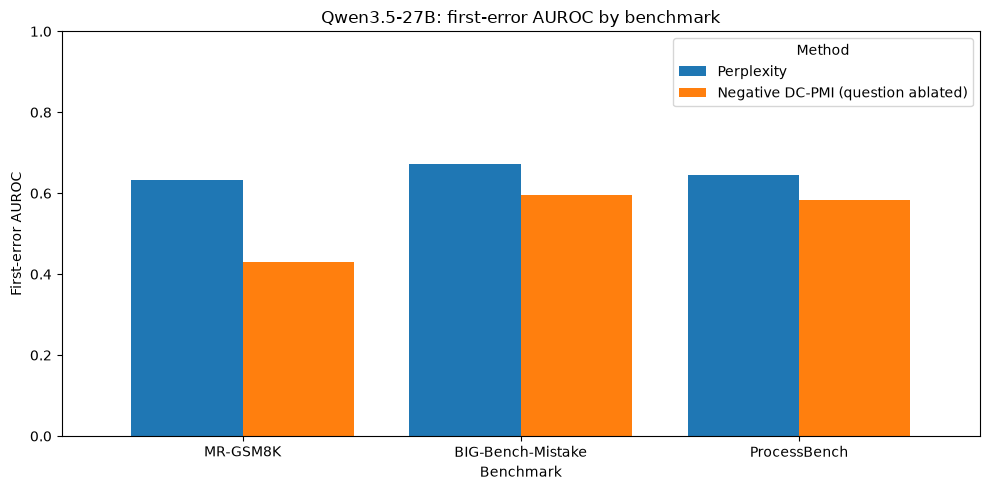

In [10]:
from sklearn.metrics import roc_auc_score

scores_27b = pmi_scores[list(MODELS).index('27B')]
auc_rows = []
for benchmark, group in scores_27b.groupby('benchmark', sort=False):
    assert group.first_error.nunique() == 2
    for metric in ('perplexity', 'dc_pmi_question_ablation'):
        auc_rows.append({
            'benchmark': benchmark, 'method': METRIC_LABELS[metric],
            'auroc': roc_auc_score(group.first_error, dc_pmi.error_evidence_score(group, metric)),
        })
auc_comparison = pd.DataFrame(auc_rows).pivot(index='benchmark', columns='method', values='auroc')
ax = auc_comparison.reindex(index=benchmarks, columns=[
    METRIC_LABELS['perplexity'], METRIC_LABELS['dc_pmi_question_ablation'],
]).plot.bar(figsize=(10, 5), rot=0, ylim=(0, 1), width=0.8)
ax.set(xlabel='Benchmark', ylabel='First-error AUROC', title='Qwen3.5-27B: first-error AUROC by benchmark')
ax.legend(title='Method')
plt.tight_layout()
plt.show()

## All models: first-error AUROC and significance by benchmark

For each model and benchmark, AUROC pools all steps across task types. The one-sided Mann–Whitney U test asks whether error-evidence scores (higher perplexity or lower DC-PMI) are higher at annotated first-error steps than at all other steps. Bars with $p \ge 0.05$ are faded; p-values are unadjusted for multiple comparisons.

In [ ]:
from scipy.stats import mannwhitneyu
from matplotlib.patches import Patch

for model, scores in zip(MODELS, pmi_scores):
    fig, ax = plt.subplots(figsize=(15, 6))
    for benchmark_index, benchmark in enumerate(benchmarks):
        group = scores.loc[scores.benchmark == benchmark]
        assert group.first_error.nunique() == 2
        for metric_index, metric in enumerate(dc_pmi.METRICS):
            evidence = dc_pmi.error_evidence_score(group, metric)
            positives = evidence.loc[group.first_error]
            negatives = evidence.loc[~group.first_error]
            auc = roc_auc_score(group.first_error, evidence)
            p_value = mannwhitneyu(positives, negatives, alternative='greater').pvalue
            x = benchmark_index + (metric_index - (len(dc_pmi.METRICS) - 1) / 2) * 0.2
            bar = ax.bar(x, auc, width=0.19, color=f'C{metric_index}')
            if p_value >= 0.05:
                bar[0].set_alpha(0.35)
            ax.bar_label(bar, labels=[f'{auc:.3f}\np={p_value:.2g}'], padding=3, fontsize=8)
    ax.axhline(0.5, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.set(xticks=range(len(benchmarks)), xticklabels=benchmarks,
           ylabel='First-error AUROC', ylim=(0, 1.17),
           title=f'Qwen3.5-{model}: pooled first-error AUROC by benchmark')
    ax.legend(handles=[Patch(color=f'C{i}', label=METRIC_LABELS[metric])
                       for i, metric in enumerate(dc_pmi.METRICS)],
              title='Metric', loc='upper left', bbox_to_anchor=(1, 1))
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


## Scores around matched error and control positions

Within each benchmark task, each error trace is paired with a distinct error-free trace of the same length; unmatched errors are dropped. Both groups use the error trace's annotated first-error step as step 0. Curves pool all three models and task types with 95% bootstrap confidence intervals across model–trace pairs. The dotted horizontal line marks each group's mean at step 0. Comparing the matched control trajectories with error trajectories helps distinguish error-specific patterns from background variation.

In [11]:
from experiment_setup.benchmarks import sample_control_and_error
from experiment_setup.plots import plot_first_error_trajectories

error_examples, control_examples = sample_control_and_error(examples, seed=42)
assert len(error_examples) == len(control_examples) > 0
assert all((e.benchmark, e.task, len(e.steps)) == (c.benchmark, c.task, len(c.steps))
           for e, c in zip(error_examples, control_examples))
print(f"Sampled n={len(error_examples)} traces contraining errors and n={len(control_examples)} control traces")

Sampled n=2678 traces contraining errors and n=2678 control traces


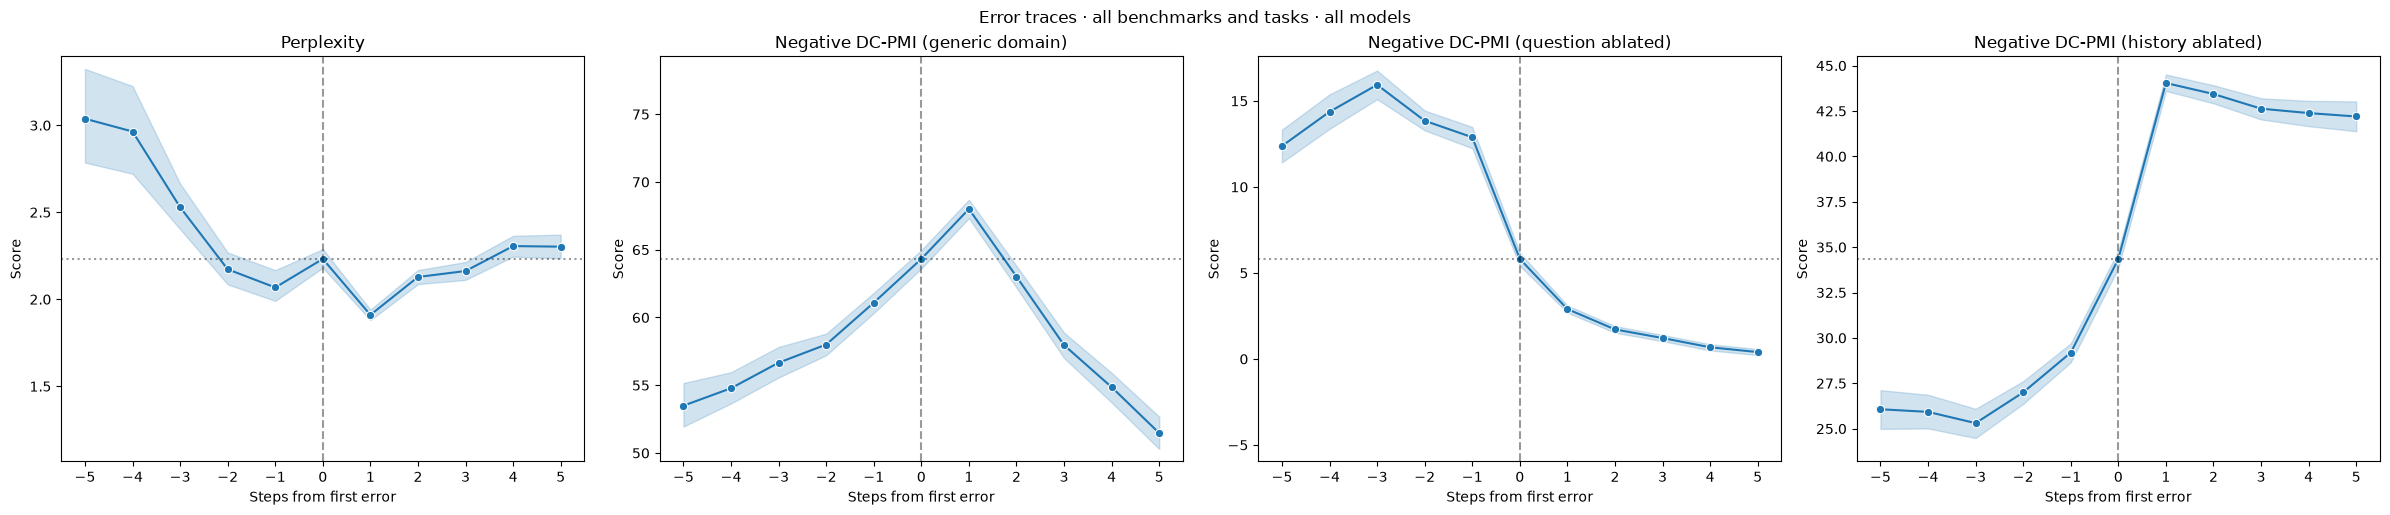

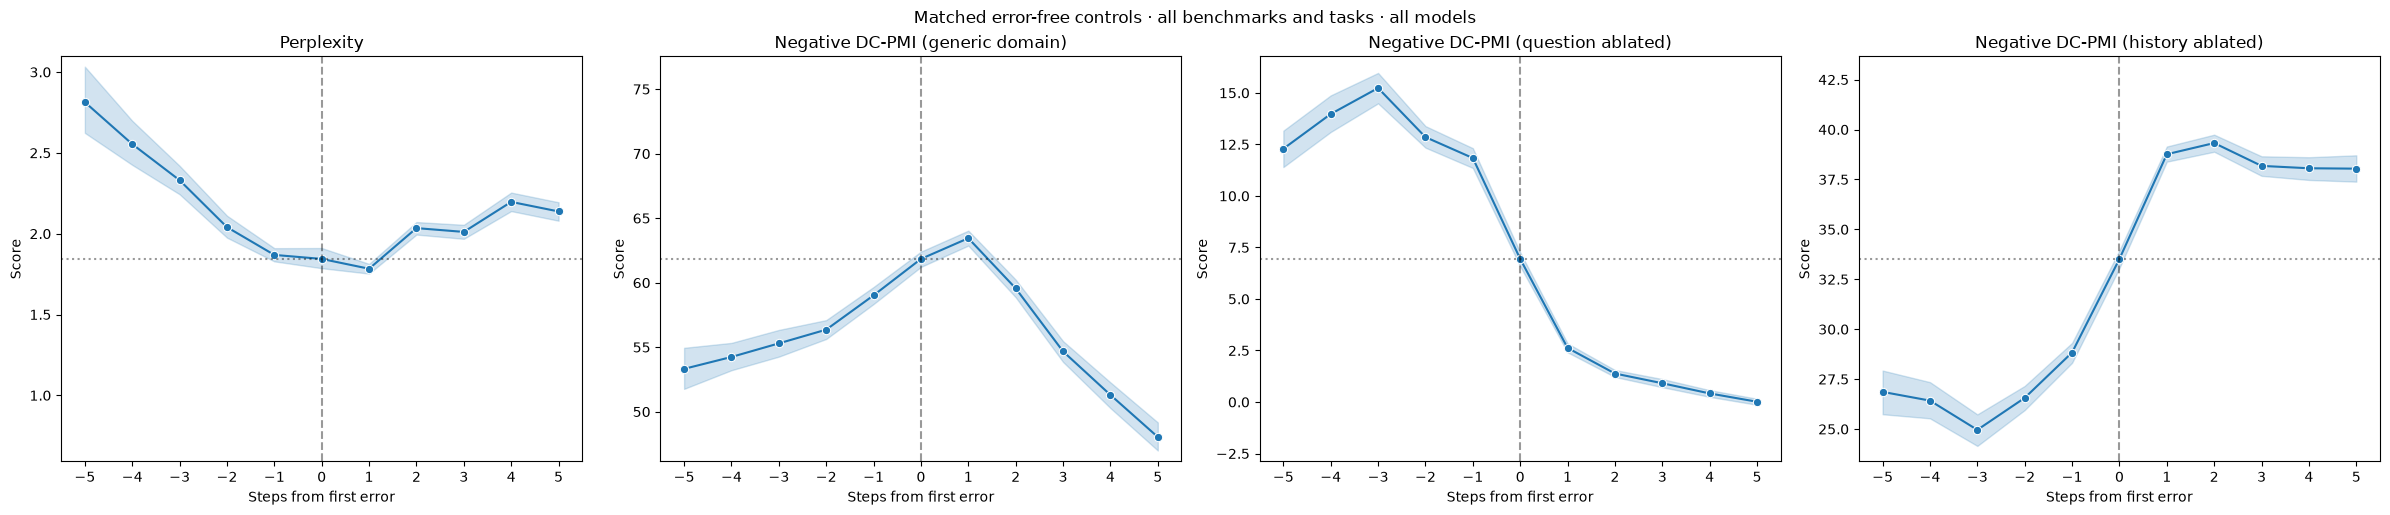

In [12]:
all_scores = pd.concat(pmi_scores, ignore_index=True)
assert all_scores[['benchmark', 'task', 'uid']].drop_duplicates().shape[0] == len(examples) * len(MODELS)
error_keys = pd.DataFrame([
    dict(benchmark=e.benchmark, task=e.task, uid=f'{model}:{e.uid}', n_steps=len(e.steps))
    for e in error_examples for model in MODELS
])
control_anchors = pd.DataFrame([
    dict(benchmark=c.benchmark, task=c.task, uid=f'{model}:{c.uid}',
         anchor=e.label, n_steps=len(c.steps))
    for e, c in zip(error_examples, control_examples) for model in MODELS
])
trace_keys = ['benchmark', 'task', 'uid']
error_scores = all_scores.merge(error_keys, on=trace_keys, how='inner', validate='many_to_one')
control_scores = all_scores.merge(control_anchors, on=trace_keys, how='inner', validate='many_to_one')
assert error_scores[trace_keys].drop_duplicates().shape[0] == len(error_examples) * len(MODELS)
assert control_scores[trace_keys].drop_duplicates().shape[0] == len(control_examples) * len(MODELS)
assert error_scores.groupby(trace_keys).size().eq(error_scores.groupby(trace_keys).n_steps.first()).all()
assert control_scores.groupby(trace_keys).size().eq(control_scores.groupby(trace_keys).n_steps.first()).all()
control_scores['first_error'] = control_scores.step.eq(control_scores.anchor)
assert control_scores.groupby(trace_keys).first_error.sum().eq(1).all()
assert error_scores.groupby(trace_keys).first_error.sum().eq(1).all()

for name, group in [('Error traces', error_scores), ('Matched error-free controls', control_scores)]:
    fig = plot_first_error_trajectories(group)
    fig.suptitle(f'{name} · all benchmarks and tasks · all models', y=1.02)
    display(fig)
    plt.close(fig)


## Scores at matched positions · 4B

Each histogram compares first-error steps with the corresponding positions in the matched error-free traces, pooled across benchmark tasks. Density normalization makes the distributions comparable.

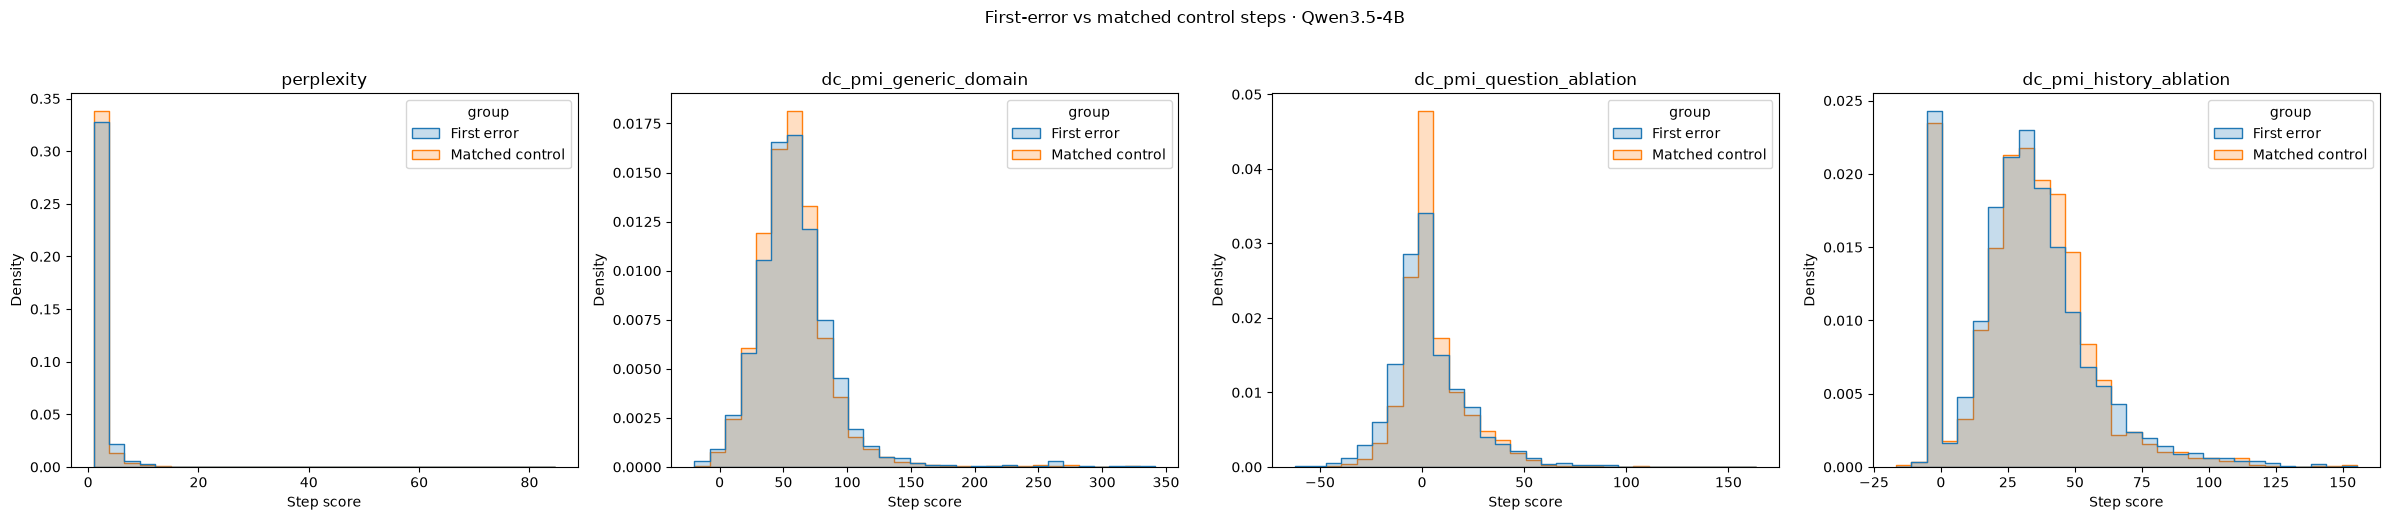

In [13]:
from experiment_setup.plots import plot_matched_step_histograms

fig = plot_matched_step_histograms(error_scores, control_scores, model='4B')
display(fig)
plt.close(fig)


## First differences at matched positions

For each metric, the step-to-step change $y_x - y_{x-1}$ is plotted separately for error traces and their matched error-free controls, using the same aligned positions as above. The first step of a trace has no preceding step, so its difference is missing.

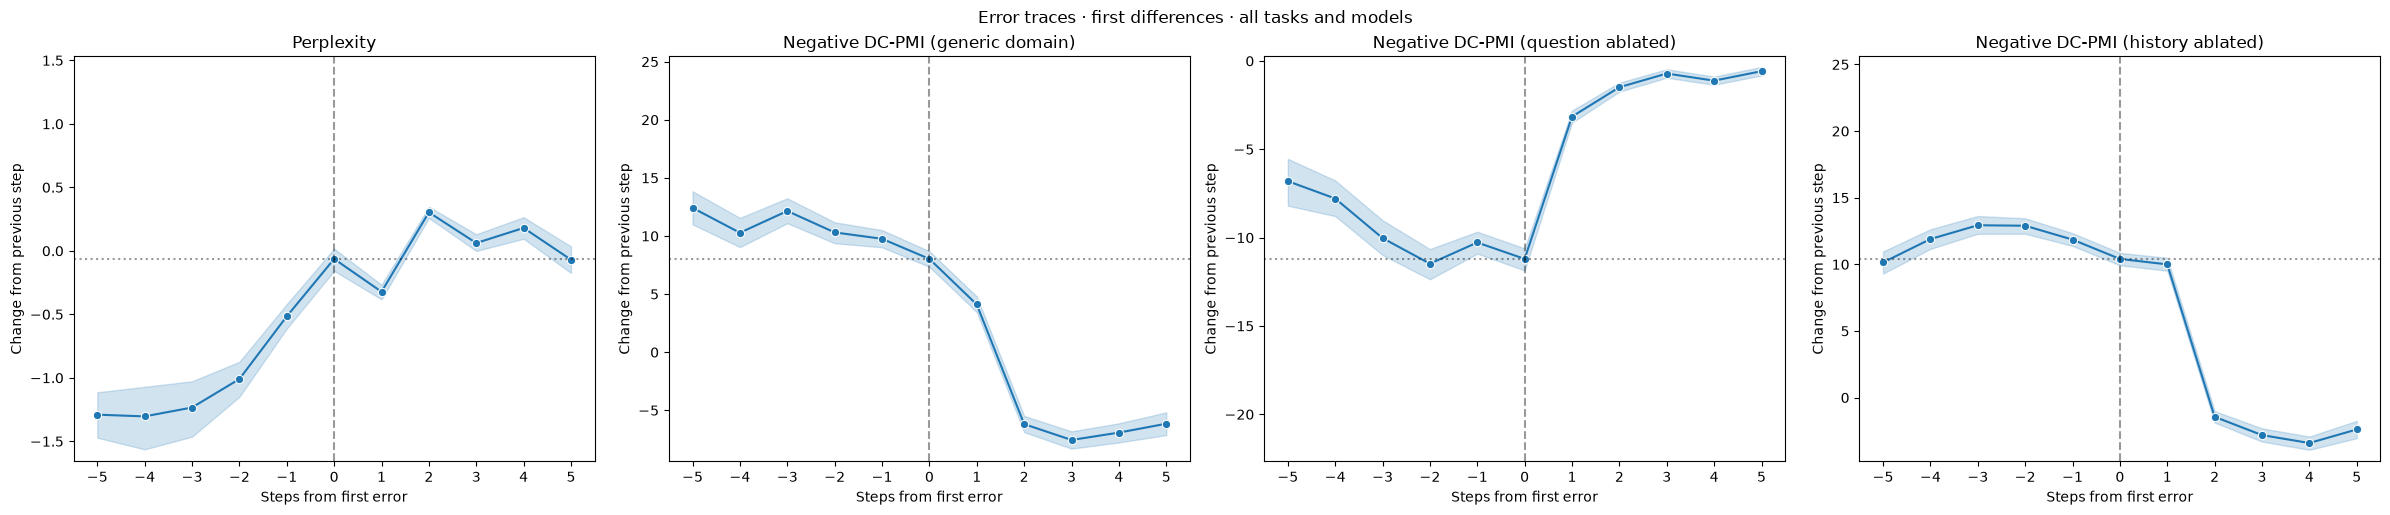

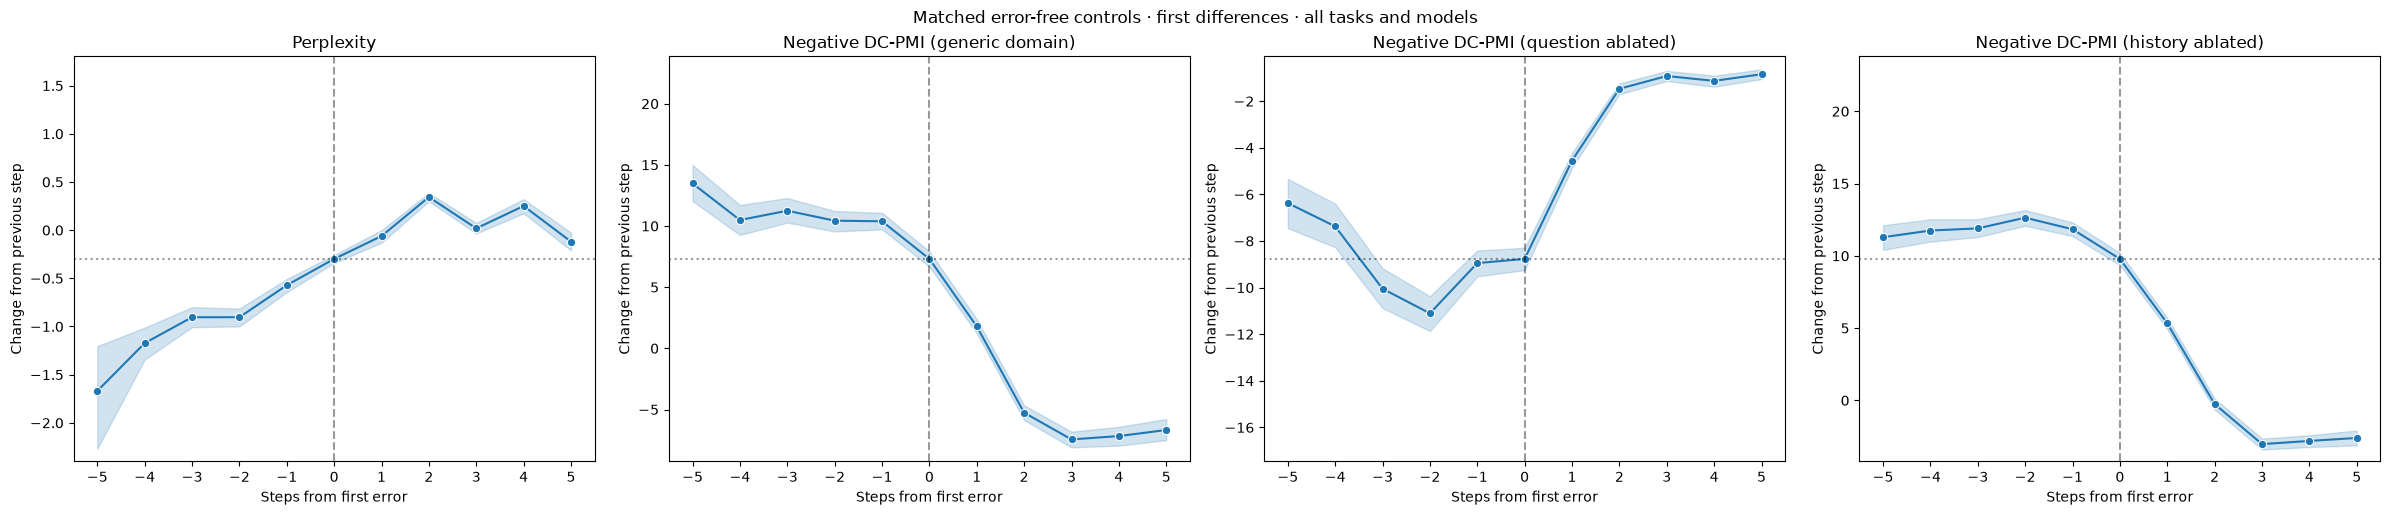

In [14]:
for name, group in [('Error traces', error_scores), ('Matched error-free controls', control_scores)]:
    difference_scores = group.sort_values(trace_keys + ['step']).copy()
    difference_scores[list(dc_pmi.METRICS)] = (
        difference_scores.groupby(trace_keys, sort=False)[list(dc_pmi.METRICS)].diff()
    )
    assert difference_scores.loc[difference_scores.step == 0, list(dc_pmi.METRICS)].isna().all().all()
    fig = plot_first_error_trajectories(difference_scores)
    for ax in fig.axes:
        ax.set_ylabel('Change from previous step')
    fig.suptitle(f'{name} · first differences · all tasks and models', y=1.02)
    display(fig)
    plt.close(fig)
